# LOSO con captura de movimiento (MVNX) sola — CPC–xLSTM a 12 Hz

**Proyecto Integrador — Equipo 1**

En `08_LOSO_CPC_sEMG_MVNX_fs12.ipynb`, agregar 30 variables MVNX a la sEMG subió el F1 macro de **0.433** (sEMG sola, 07_LOSO) a **0.880**, en los 12 sujetos (p = 0.0005). Falta saber **de dónde viene** esa mejora: ¿la sEMG sigue aportando algo, o el modelo se apoya casi sólo en el movimiento?

Este notebook entrena **el mismo modelo con sólo las 30 variables MVNX**, sin la sEMG, y lo compara con los dos anteriores. El resultado sirve para decidir cómo integrar las dos modalidades.

## Preguntas

1. ¿Cuánto rinde MVNX por sí sola en una persona nueva?
2. ¿La sEMG agrega algo sobre MVNX (sEMG + MVNX − MVNX sola)? ¿En qué actividades y en qué tareas?

## Diseño

| Elemento | Decisión | Por qué |
|---|---|---|
| Entrada | Las **30 variables MVNX** del 08, con la misma preparación; sin sEMG | Aísla el aporte del movimiento |
| Preparación | Igual que el 08 (selección, coordenadas relativas, ipsi/contra, escalado q95 − q5), **sin repetir los gráficos** | Cada transformación ya está justificada en la sección 3 del 08 |
| Ventanas y etiquetas | **Exactamente las del 08**: etiqueta sEMG del instante final | La comparación con el 08 es ventana por ventana; se verifica en la sección 4 |
| Modelo y método | El del 07_LOSO y el 08 (sLSTM, horizonte de 1 s, `c_T`, ajuste fino preentrenado); sólo cambia `n_channels` (30) | Mismo protocolo, misma configuración |
| Rondas y semilla | Las 12 rondas LOSO, con la semilla 0 | Emparejado con el 08; 13 y 14 siguen cerrados |
| Comparaciones | sEMG sola (07_LOSO), **MVNX sola (este notebook)**, sEMG + MVNX (08) | Las tres en los mismos sujetos y con la misma semilla |

**Nota sobre los ensayos bimanuales.** Se conservan los dos ensayos por brazo del 08. Sin sEMG, los dos tienen el mismo MVNX (sólo cambia el orden ipsi/contra) y casi la misma etiqueta. Esto no afecta la validez de LOSO, porque los dos son del mismo sujeto. Lo que sí hacen es dar el doble de peso a los ensayos bimanuales, igual que en el 08, y así las tres comparaciones siguen siendo sobre las mismas ventanas.

# 1. Configuración

In [1]:
import copy, json, math, time
from dataclasses import dataclass
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.stats import skew, wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Diseño -----------------------------
TARGET_FS = 12
QUICK = False                          # True = corrida de humo (2 rondas, pocas épocas, carpeta aparte)
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
SEEDS = (0,)                           # la misma semilla del 08

# ----------------------------- Configuración congelada (mejor del 07_LOSO a 12 Hz) -----------------------------
KIND = "sLSTM"
HORIZON_S = 1.0
BATCH_MODE = "mismo_sujeto"
REP = "c_T"
MAX_PRED_HEADS = 12
METHOD = "ajuste fino preentrenado"    # el único método que se entrena aquí

# ----------------------------- Entrenamiento (iguales al 07_LOSO) -----------------------------
EPOCHS_MAX, EVAL_EVERY, PATIENCE = 20, 2, 3
BATCH_SIZE, LR, GRAD_CLIP = 128, 5e-4, 1.0
PROBE_TRAIN_MAX = 15_000
FINETUNE_EPOCHS, FINETUNE_PATIENCE, FINETUNE_BATCH = 15, 3, 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
SCALER_FIT_POINTS = 250_000
RERUN = False
SEED_DATA = 0
DEVICE_OVERRIDE = None

FOLDS = CV_SUBJECTS
STEPS_CAP = EVAL_CAP = FT_TRAIN_CAP = None
if QUICK:
    FOLDS, SEEDS = (1, 2), (0,)
    EPOCHS_MAX, EVAL_EVERY, PATIENCE = 2, 1, 1
    PROBE_TRAIN_MAX, STEPS_CAP, EVAL_CAP, FT_TRAIN_CAP, FINETUNE_EPOCHS = 2_000, 4, 1_500, 2_000, 1
# ---------------------------------------------------------------------------

if DEVICE_OVERRIDE:
    DEVICE = torch.device(DEVICE_OVERRIDE)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"     # exportación del 07_Sincronizacion
AV2_DIR = REPO_DIR / "notebooks" / "_cache" / "avance2" / f"fs{TARGET_FS}"   # exportación sEMG que usó el 07_LOSO
LOSO_DIR = REPO_DIR / "checkpoints" / f"cpc07_loso_fs{TARGET_FS}"            # predicciones del 07_LOSO (sEMG sola)
FUSED_DIR = REPO_DIR / "checkpoints" / f"cpc08_loso_semg_mvnx_fs{TARGET_FS}"  # predicciones del 08 (sEMG + MVNX)
TAG = f"fs{TARGET_FS}" + ("_quick" if QUICK else "")
RUN_DIR = REPO_DIR / "checkpoints" / f"cpc09_loso_mvnx_{TAG}"
SUMMARY_CSV = REPO_DIR / "notebooks" / "_cache" / f"cpc09_loso_mvnx_{TAG}_resultados.csv"
LOG_FILE = RUN_DIR / "progreso.log"
RUN_DIR.mkdir(parents=True, exist_ok=True)
for d in (SYNC_DIR / "un_brazo", SYNC_DIR / "bimanual", AV2_DIR, LOSO_DIR, FUSED_DIR):
    assert d.exists(), f"Falta {d.relative_to(REPO_DIR)}"
assert not set(CV_SUBJECTS) & set(TEST_SUBJECTS)

AV2_META = json.loads((AV2_DIR / "metadata.json").read_text())
SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
assert AV2_META["target_fs"] == SYNC_META["target_fs"] == TARGET_FS and AV2_META["label_rule"] == "final_instant"
LABELS = AV2_META["label_order"]
assert SYNC_META["label_order"] == LABELS
WIN, CPC_HOP, SUP_HOP, TAIL = AV2_META["window_len"], AV2_META["cpc_hop"], AV2_META["supervised_hop"], AV2_META["tail_steps"]

def horizons_for(seconds, fs=TARGET_FS, max_heads=MAX_PRED_HEADS):
    n = max(1, int(round(seconds * fs)))
    if n <= max_heads:
        return tuple(range(1, n + 1))
    return tuple(int(k) for k in np.unique(np.round(np.linspace(n / max_heads, n, max_heads)).astype(int)))

HORIZONS = horizons_for(HORIZON_S)

def inner_validation_subject(held_out):
    """El siguiente sujeto de la lista (circular) decide la parada temprana."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
LABEL_COLORS = {"N": "#9e9e9e", "LF": "#1f77b4", "K": "#ff7f0e", "PT": "#2ca02c", "LT": "#d62728", "W": "#9467bd", "PF": "#8c564b"}
print("PyTorch:", torch.__version__, "| dispositivo:", DEVICE, "| QUICK:", QUICK)
print("Corridas:", RUN_DIR.relative_to(REPO_DIR))
print(f"Configuración: {KIND} · horizontes {HORIZONS} ({1000 * HORIZONS[-1] / TARGET_FS:.0f} ms) · {BATCH_MODE} · {REP} · "
      f"ventana {WIN} pasos ({WIN / TARGET_FS:.0f} s)")

PyTorch: 2.11.0 | dispositivo: mps | QUICK: False
Corridas: checkpoints/cpc09_loso_mvnx_fs12
Configuración: sLSTM · horizontes (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12) (1000 ms) · mismo_sujeto · c_T · ventana 48 pasos (4 s)


# 2. Datos

Se construyen los mismos ensayos por brazo que en el 08 (ver su sección 2) y después se **descarta la sEMG**: la serie queda con las 30 variables MVNX. La etiqueta de cada instante sigue siendo la sEMG de ese brazo, para que las ventanas sean las mismas que en el 07_LOSO y el 08.

La sección 3 del 08 muestra y justifica cada transformación con gráficos de antes y después:

- **3.1 selección de variables:** 782 columnas → 30;
- **3.2 invariancia a la posición y al rumbo:** coordenadas relativas al cuerpo y magnitudes;
- **3.3 ipsi/contra:** cada variable se ordena respecto al brazo con sEMG;
- **3.4 escalado:** (x − mediana) / (q95 − q5);
- **3.5 bimanual:** cada ensayo se parte en dos ensayos por brazo.

In [2]:
SIDE_NAME = {"L": "Left", "R": "Right"}
OTHER = {"L": "R", "R": "L"}

# Columnas MVNX crudas que se necesitan para calcular las variables de la sección 3
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head","jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}


def derive(raw, side):
    """Las 30 variables MVNX (sección 3) a partir de las columnas crudas. `side` es el brazo con sEMG."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    roles = (("ipsi", SIDE_NAME[side]), ("contra", SIDE_NAME[OTHER[side]]))
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for rol, s in roles:
        out[f"{rol}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{rol}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{rol}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{rol}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{rol}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{rol}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for rol, s in roles:
        out[f"{rol}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{rol}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                              col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for rol, s in roles:
        out[f"{rol}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    for rol, s in roles:
        out[f"{rol}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{rol}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"


def load_set(conjunto):
    base = SYNC_DIR / conjunto
    cols = json.loads((base / "columns.json").read_text())
    names = [c["name"] for c in cols["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        data = {k: z[k] for k in z.files if k != "mvnx"}
        full = z["mvnx"]
    data["mvnx"] = full[:, [pos[c] for c in RAW_COLUMNS]]
    rows = np.sort(np.random.default_rng(SEED_DATA).choice(len(full), 20_000, replace=False))
    return data, pd.read_csv(base / "trials.csv"), cols, names, full[rows]


raw_sets = {}
rows, emg_parts, mv_parts, lab_parts, time_parts, offsets = [], [], [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    data, tr, cols, names, sample = load_set(conjunto)
    raw_sets[conjunto] = {"data": data, "trials": tr}
    if conjunto == "un_brazo":
        FULL_NAMES, FULL_SAMPLE = names, sample
    emg_names = [c["name"] for c in cols["emg"]]
    for r in tr.itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        for side in (("L", "R") if conjunto == "bimanual" else (r.side,)):
            if conjunto == "bimanual":
                emg = data["emg"][sl][:, [i for i, n in enumerate(emg_names) if n.startswith(f"{side}_")]]
                lab = data[f"label_emg_{side}"][sl]
            else:
                emg, lab = data["emg"][sl], data["label_emg"][sl]
            assert emg.shape[1] == 8
            mv, FEATURES = derive(data["mvnx"][sl], side)
            rows.append({"trial_idx": len(rows), "file": getattr(r, f"emg_file_{side}"), "mvnx_file": r.mvnx_file,
                         "conjunto": conjunto, "subject": r.subject, "task": r.task, "side": side, "load_kg": r.load_kg,
                         "condition": r.condition, "split": r.split, "offset": offsets[-1], "n_steps": r.n_steps,
                         "desfase_s": getattr(r, f"desfase_eventos_{side}_s"), "validacion_dudosa": bool(r.validacion_dudosa)})
            emg_parts.append(emg); mv_parts.append(mv); lab_parts.append(lab); time_parts.append(data["time_s"][sl])
            offsets.append(offsets[-1] + r.n_steps)
del sample, data, raw_sets

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])
EMG_NAMES = [f"Norm_RMS_{i}" for i in range(1, 9)]
CHANNELS = EMG_NAMES + FEATURES
N_EMG, N_MV = len(EMG_NAMES), len(FEATURES)
signals_raw = np.concatenate([np.concatenate(emg_parts), np.concatenate(mv_parts)], axis=1).astype(np.float32)
labels_series = np.concatenate(lab_parts).astype(np.int64)
time_series = np.concatenate(time_parts)
N_CH = signals_raw.shape[1]
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1" and i >= N_EMG]
del emg_parts, mv_parts, lab_parts, time_parts
assert not np.isnan(signals_raw).any(), "Hay NaN en las variables elegidas"
assert trials["file"].is_unique

print(f"{len(trials)} ensayos por brazo | {len(signals_raw):,} instantes | {N_CH} canales ({N_EMG} sEMG + {N_MV} MVNX)")
display(trials.groupby(["conjunto", "task"]).agg(ensayos=("file", "size"), sujetos=("subject", "nunique"),
                                               horas=("n_steps", lambda n: n.sum() / TARGET_FS / 3600),
                                               marcados=("validacion_dudosa", "sum")).round(2))

av2_trials = pd.read_csv(AV2_DIR / "trials.csv")
missing = av2_trials[~av2_trials["file"].isin(trials["file"])]
assert trials["file"].isin(av2_trials["file"]).all(), "Hay ensayos sincronizados que no están en el avance 2"
print(f"Ensayos sEMG del avance 2 (07_LOSO): {len(av2_trials)} | sincronizados: {len(trials)} | "
      f"sin MVNX válido: {len(missing)} (excluidos en el 07_Sincronizacion):")
display(missing[["file", "subject", "task"]].reset_index(drop=True))

627 ensayos por brazo | 426,026 instantes | 38 canales (8 sEMG + 30 MVNX)


ensayos  sujetos  horas  marcados
conjunto task                                      
bimanual MMH_Bim      244       14   4.20        46
un_brazo Isokin       220       14   2.73        60
         MMH_One      163       14   2.93        27

Ensayos sEMG del avance 2 (07_LOSO): 638 | sincronizados: 627 | sin MVNX válido: 11 (excluidos en el 07_Sincronizacion):


,file,subject,task
0,Subj_06_MMH_One_L_02kg_Trial_3_EMG_data.csv,6,MMH_One
1,Subj_07_MMH_Bim_L_08kg_Trial_3_EMG_data.csv,7,MMH_Bim
2,Subj_07_MMH_Bim_L_12kg_Trial_1_EMG_data.csv,7,MMH_Bim
3,Subj_07_MMH_Bim_L_12kg_Trial_2_EMG_data.csv,7,MMH_Bim
4,Subj_07_MMH_One_L_04kg_Trial_2_EMG_data.csv,7,MMH_One
5,Subj_09_MMH_One_R_02kg_Trial_3_EMG_data.csv,9,MMH_One
6,Subj_11_Isokin_R_02kg_St_EMG_data.csv,11,Isokin
7,Subj_13_MMH_One_L_04kg_Trial_2_EMG_data.csv,13,MMH_One
8,Subj_14_Isokin_L_02kg_60bpm_EMG_data.csv,14,Isokin
9,Subj_14_MMH_Bim_L_02kg_Trial_1_EMG_data.csv,14,MMH_Bim


In [3]:
# Sin sEMG: la serie queda sólo con las variables MVNX
signals_raw = np.ascontiguousarray(signals_raw[:, N_EMG:])
CHANNELS, N_CH = list(FEATURES), N_MV
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]
assert signals_raw.shape[1] == N_CH == 30


def fit_scaler(train_subjects, seed=SEED_DATA):
    """MVNX: clip (q0.1 %, q99.9 %) + (x − mediana) / (q95 − q5), como el 08. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in
            {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


check = fit_scaler(tuple(range(1, 11)))
scaled = apply_scaler(check)
print(f"Entrada: {N_CH} variables MVNX | escaladas con los sujetos 1–10: [{scaled.min():.1f}, {scaled.max():.1f}]")
del scaled

Entrada: 30 variables MVNX | escaladas con los sujetos 1–10: [-3.2, 4.6]


# 3. Ventanas

Mismas reglas que el 08: 48 pasos, una ventana CPC cada 24 pasos y una supervisada cada 6, con la etiqueta sEMG del instante final. La celda comprueba que **las ventanas evaluadas son idénticas a las del 08**, ronda por ronda (mismo índice y misma etiqueta). Así, la comparación con sEMG + MVNX es exacta.

In [4]:
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] >= 0]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and not cpc_cv["subject"].isin(TEST_SUBJECTS).any()

av2_sup = pd.read_csv(AV2_DIR / "supervised_index.csv.gz")
av2_sup_cv = av2_sup[av2_sup["subject"].isin(CV_SUBJECTS)]
compare = pd.DataFrame({"07_LOSO (avance 2)": av2_sup_cv.groupby("subject").size(), "sincronizadas": sup_cv.groupby("subject").size()})
compare["conservadas"] = (compare["sincronizadas"] / compare["07_LOSO (avance 2)"]).map("{:.0%}".format)
print(f"Ventanas supervisadas (sujetos 1–12): {len(sup_cv):,} | ventanas CPC: {len(cpc_cv):,}")
display(compare.T)
display(pd.DataFrame({"07_LOSO (avance 2)": av2_sup_cv["target"].value_counts(normalize=True).sort_index(),
                      "sincronizadas": sup_cv["target"].value_counts(normalize=True).sort_index()})
        .rename(index=dict(enumerate(LABELS))).T.round(3))

S_T = None
WIN_RANGE = torch.arange(WIN, device=DEVICE)

def set_series(scaled):
    """Sube al dispositivo la serie escalada de la ronda actual."""
    global S_T
    S_T = torch.from_numpy(np.ascontiguousarray(scaled.T)).to(DEVICE)

def starts_of(frame):
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()

def get_windows(starts):
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


fused_runs = {(r["held_out"], r["seed"]): r for r in (json.loads(p.read_text()) for p in sorted(FUSED_DIR.glob("ronda_*.json")))}
assert fused_runs, "Faltan las rondas del 08"
for (s, seed), r in fused_runs.items():
    expected = sup_cv[sup_cv["subject"] == s]
    assert r["index"] == expected.index.tolist() and r["y"] == expected["target"].tolist(), f"Ventanas distintas en la ronda {s}"
print(f"Ventanas idénticas a las del 08 en sus {len(fused_runs)} rondas")

Ventanas supervisadas (sujetos 1–12): 51,814 | ventanas CPC: 14,500


subject,1,2,3,4,5,6,7,8,9,10,11,12
07_LOSO (avance 2),5076,3633,4294,4023,4402,3959,4602,4719,4508,4017,5954,4036
sincronizadas,4958,3558,4212,4009,4398,3823,4043,4635,4407,3918,5864,3989
conservadas,98%,98%,98%,100%,100%,97%,88%,98%,98%,98%,98%,99%


target,N,LF,K,PT,LT,W,PF
07_LOSO (avance 2),0.429,0.097,0.087,0.146,0.090,0.08,0.071
sincronizadas,0.425,0.097,0.088,0.148,0.091,0.08,0.072


Ventanas idénticas a las del 08 en sus 12 rondas


# 4. Referencias: sEMG sola (07_LOSO) y sEMG + MVNX (08)

- **sEMG sola:** las predicciones guardadas del 07_LOSO, filtradas a los ensayos sincronizados (sección 5 del 08).
- **sEMG + MVNX:** las predicciones guardadas del 08, en las mismas ventanas que este notebook.

In [5]:
base_rows = []
for p in sorted(LOSO_DIR.glob("ronda_*.json")):
    r = json.loads(p.read_text())
    w = av2_sup_cv[av2_sup_cv["subject"] == r["held_out"]]
    y, pred = np.asarray(r["y"]), np.asarray(r["pred"][METHOD])
    assert len(w) == len(y) and (w["target"].to_numpy() == y).all(), f"El orden de {p.name} no coincide con el índice"
    f1_all = f1_score(y, pred, average="macro")
    assert abs(f1_all - r["metrics"][METHOD]["f1_macro"]) < 1e-9
    keep = w["file"].isin(trials["file"]).to_numpy()
    base_rows.append({"sujeto": r["held_out"], "semilla": r["seed"], "F1 todas las ventanas": f1_all,
                      "F1 ensayos sincronizados": f1_score(y[keep], pred[keep], average="macro"),
                      "ventanas conservadas": keep.mean(), "y": y[keep], "pred": pred[keep],
                      "file": w["file"].to_numpy()[keep]})
baseline = pd.DataFrame(base_rows)

def baseline_f1(subject, seed):
    return float(baseline.loc[(baseline["sujeto"] == subject) & (baseline["semilla"] == seed), "F1 ensayos sincronizados"].iloc[0])

view = baseline.pivot(index="sujeto", columns="semilla", values=["F1 todas las ventanas", "F1 ensayos sincronizados"])
view.loc["media"] = view.mean()
print(f"07_LOSO, {METHOD}: el F1 con todas las ventanas reproduce el notebook 07; la línea base es el F1 en los ensayos sincronizados.")
display(view.round(3))


def fused_f1(subject, seed):
    return fused_runs[(subject, seed)]["metrics"]["f1_macro"]

07_LOSO, ajuste fino preentrenado: el F1 con todas las ventanas reproduce el notebook 07; la línea base es el F1 en los ensayos sincronizados.


F1 todas las ventanas        F1 ensayos sincronizados       
semilla                     0      1                        0      1
sujeto                                                              
1                       0.424  0.431                    0.424  0.431
2                       0.337  0.393                    0.337  0.393
3                       0.547  0.520                    0.547  0.520
4                       0.422  0.425                    0.422  0.425
5                       0.429  0.419                    0.429  0.419
6                       0.397  0.342                    0.399  0.341
7                       0.333  0.342                    0.334  0.346
8                       0.473  0.474                    0.473  0.474
9                       0.469  0.445                    0.468  0.444
10                      0.397  0.412                    0.397  0.412
11                      0.511  0.607                    0.511  0.607
12                      0.454  0.483                    0.454  0.483
media                   0.433  0.441                    0.433  0.441

# 5. Modelo

Las mismas clases del 07_LOSO y del 08. Sólo cambia `n_channels`, que se toma de la serie (30).

In [6]:
@dataclass
class CPCConfig:
    """
    Hiperparámetros de CPC (los mismos del notebook 01), más `pred_horizons`:
    la lista de horizontes k que se predicen. Vacía = k = 1..n_pred_steps, el comportamiento original.
    """
    # --- entrada ---
    n_channels: int = 6

    # --- g_enc: encoder convolucional ---
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2

    # --- g_ar: modelo autorregresivo ---
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2

    # --- predicción / pérdida contrastiva ---
    n_pred_steps: int = 12                  # K: número de horizontes
    n_anchors: int = 4                      # nº de instantes de anclaje por batch de entrenamiento
    pred_horizons: tuple = ()               # NUEVO: horizontes k (en pasos); vacío = 1..n_pred_steps

    @property
    def horizons(self) -> tuple:
        return tuple(self.pred_horizons) or tuple(range(1, self.n_pred_steps + 1))

    @property
    def z_dim(self) -> int:
        return self.enc_channels[-1]

    @property
    def c_dim(self) -> int:
        return self.ar_hidden_size

In [7]:
class CausalEncoder(nn.Module):
    """g_enc causal: bloques Conv1d -> ReLU -> Dropout sin stride (Haresamudram et al., 2020),
    con relleno sólo a la izquierda: z_t depende de x_{t-3..t}, nunca del futuro.

        x: (B, n_channels, T)  -->  z: (B, z_dim, T)
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z

In [8]:
class AutoRegressive(nn.Module):
    """
    g_ar: modelo autorregresivo genérico (GRU multicapa).

        z: (B, L, z_dim)  -->  c: (B, L, c_dim)

    Los parámetros de GRU se especifican en la clase cfg. De acuerdo al paper: 
    - input_size: 128
    - hidden_Size: 256
    - num_layer: 2

    c[:, t] resume z[:, :t+1] de forma causal (una GRU nunca mira el futuro),
    que es la propiedad necesaria para usar c_t como predictor de z_{t+k}.

    Arquitectura (Haresamudram, Essa & Plötz, 2020): GRU de 2 capas con 256
    unidades ocultas y dropout entre capas.
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.gru = nn.GRU(
            input_size=cfg.z_dim,
            hidden_size=cfg.ar_hidden_size,
            num_layers=cfg.ar_num_layers,
            dropout=cfg.ar_dropout if cfg.ar_num_layers > 1 else 0.0,  # PyTorch exige 0 si num_layers==1
            batch_first=True,
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        c, _ = self.gru(z)        # c: (B, L, c_dim) - Hace un loop sobre todo el eje temporal toma el c_{t-1} e incorpora el nuevo paso z_t
        return c

In [9]:
class Predictor(nn.Module):
    """
    Cabezas de predicción log-bilineal: una W_k (sin sesgo) por cada horizonte de cfg.horizons.

        c_t: (B, c_dim) -> (n_horizontes, B, z_dim),  con pred_k = W_k c_t ≈ z_{t+k}
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.horizons = cfg.horizons
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in self.horizons])

    def forward(self, c_t: torch.Tensor) -> torch.Tensor:
        return torch.stack([head(c_t) for head in self.heads], dim=0)


class InfoNCE(nn.Module):
    """
    Pérdida contrastiva de CPC (Ec. 4) con negativos de minibatch, para cada horizonte de la lista.
    Para el horizonte k, el positivo de la secuencia i es z_{t+k}^(i) y los negativos son los
    z_{t+k}^(j) (j != i) de las otras secuencias del batch.
    """

    def __init__(self, horizons: tuple):
        super().__init__()
        self.horizons = tuple(horizons)

    def forward(self, preds: torch.Tensor, z: torch.Tensor, t: int):
        """
        preds: (n_horizontes, B, z_dim) · z: (B, L, z_dim) · t: instante de anclaje
        Devuelve (loss_mean, loss_per_k, acc_per_k), los dos últimos de forma (n_horizontes,).
        """
        H, B, _ = preds.shape
        target = torch.arange(B, device=preds.device)
        loss_per_k = torch.zeros(H, device=preds.device)
        acc_per_k = torch.zeros(H, device=preds.device)
        for j, k in enumerate(self.horizons):
            logits = preds[j] @ z[:, t + k, :].t()          # (B, B): S_ij = pred_i · z_{t+k}^(j)
            loss_per_k[j] = F.cross_entropy(logits, target)
            acc_per_k[j] = (logits.argmax(dim=1) == target).float().mean()
        return loss_per_k.mean(), loss_per_k, acc_per_k.detach()


class CPCModel(nn.Module):
    """Modelo CPC completo (Encoder + g_ar + Predictor + InfoNCE), con horizontes de cfg.horizons."""

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)          # encoder causal (sección 3.1)
        self.ar = AutoRegressive(cfg)
        self.predictor = Predictor(cfg)
        self.info_nce_loss = InfoNCE(cfg.horizons)

    def encode(self, x: torch.Tensor):
        """x: (B, n_channels, T) -> z: (B, T, z_dim), c: (B, T, c_dim)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)

    def anchor_range(self, L: int):
        lo, hi = max(1, L // 8), L - max(self.cfg.horizons)   # deja sitio para leer z_{t+k_máx}
        if hi <= lo:
            raise ValueError(f"Ventana T={L} demasiado corta para el horizonte {max(self.cfg.horizons)}")
        return lo, hi

    def info_nce(self, x: torch.Tensor, anchors=None):
        z, c = self.encode(x)
        if anchors is None:
            anchors = torch.randint(*self.anchor_range(z.shape[1]), size=(self.cfg.n_anchors,)).tolist()
        losses, accs = [], []
        for t in anchors:
            _, loss_per_k, acc_per_k = self.info_nce_loss(self.predictor(c[:, t, :]), z, t)
            losses.append(loss_per_k)
            accs.append(acc_per_k)
        loss_per_k = torch.stack(losses).mean(dim=0)
        acc_per_k = torch.stack(accs).mean(dim=0)
        return loss_per_k.mean(), loss_per_k, acc_per_k

In [10]:
class BlockDiagonalLinear(nn.Module):
    """
    Capa lineal con matriz de pesos block-diagonal: cada "head" (bloque) solo mezcla sus propias
    dimensiones. Es la forma en que xLSTM limita la mezcla entre celdas (sLSTM) o abarata las
    proyecciones q, k, v (mLSTM).

        x: (..., dim) -> (..., dim)     con n_blocks bloques de tamaño dim // n_blocks
    """

    def __init__(self, dim: int, n_blocks: int, bias: bool = True):
        super().__init__()
        assert dim % n_blocks == 0, "dim debe ser múltiplo de n_blocks"
        self.n_blocks, self.block = n_blocks, dim // n_blocks
        self.weight = nn.Parameter(torch.randn(n_blocks, self.block, self.block) / math.sqrt(self.block))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shape = x.shape
        x = x.reshape(*shape[:-1], self.n_blocks, self.block)
        y = torch.einsum("...nd,ned->...ne", x, self.weight).reshape(shape)
        return y if self.bias is None else y + self.bias

In [11]:
class sLSTMCell(nn.Module):
    """
    Celda sLSTM (Beck et al. 2024, Ec. 34-40, con estabilización Ec. 15-17).

        x: (B, T, dim) -> h: (B, T, dim)

    Diferencias con la LSTM clásica:
      - compuerta de entrada EXPONENCIAL  i_t = exp(ĩ_t)  (permite "revisar" decisiones de memoria)
      - estado normalizador  n_t = f_t n_{t-1} + i_t,  y  h_t = o_t * c_t / n_t
      - estado estabilizador m_t para que exp() no desborde (no cambia el resultado)
      - memory mixing por heads: la recurrencia R h_{t-1} es block-diagonal (n_heads bloques)

    Es recurrente (no paralelizable): recorre el tiempo paso a paso, igual que la GRU.
    """

    def __init__(self, dim: int, n_heads: int):
        super().__init__()
        self.dim = dim
        self.W = nn.Linear(dim, 4 * dim)                                     # entrada -> z, i, f, o
        self.R = nn.ModuleList([BlockDiagonalLinear(dim, n_heads, bias=False) for _ in range(4)])
        with torch.no_grad():                                                # sesgo de la forget gate en [3, 6]
            self.W.bias[2 * dim:3 * dim] = torch.linspace(3.0, 6.0, dim)    # (Tabla 2 del paper): al inicio "recuerda"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, D = x.shape
        Wx = self.W(x)                                                       # parte de la entrada, para todo t a la vez
        h = c = n = m = x.new_zeros(B, D)
        outputs = []
        for t in range(T):
            Rh = torch.cat([r(h) for r in self.R], dim=-1)                   # parte recurrente (memory mixing)
            z_pre, i_pre, f_pre, o_pre = (Wx[:, t] + Rh).chunk(4, dim=-1)
            log_f = F.logsigmoid(f_pre)                                      # forget gate sigmoide, en log
            m_new = torch.maximum(log_f + m, i_pre)                          # Ec. 15: estabilizador
            i_gate = torch.exp(i_pre - m_new)                                # Ec. 16: i' (exponencial estabilizada)
            f_gate = torch.exp(log_f + m - m_new)                            # Ec. 17: f'
            c = f_gate * c + i_gate * torch.tanh(z_pre)                      # Ec. 34: estado de celda
            n = f_gate * n + i_gate                                          # Ec. 35: normalizador
            h = torch.sigmoid(o_pre) * c / n                                 # Ec. 36: estado oculto
            m = m_new
            outputs.append(h)
        return torch.stack(outputs, dim=1)

In [12]:
class sLSTMBlock(nn.Module):
    """
    Bloque residual sLSTM con "post up-projection" (Fig. 10 del paper, sin la convolución opcional):

        x -> LayerNorm -> sLSTM (n_heads) -> GroupNorm -> (+x)
          -> LayerNorm -> MLP con compuerta (factor 4/3, GeLU) -> (+x)
    """

    def __init__(self, dim: int, n_heads: int, dropout: float, proj_factor: float = 4 / 3):
        super().__init__()
        inner = int(round(proj_factor * dim))
        self.ln1, self.ln2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.cell = sLSTMCell(dim, n_heads)
        self.gn = nn.GroupNorm(n_heads, dim)                                 # LayerNorm por head
        self.up_a, self.up_b = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.cell(self.ln1(x))
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape)
        x = x + self.drop(h)
        y = self.ln2(x)
        return x + self.drop(self.down(self.up_a(y) * F.gelu(self.up_b(y))))

In [13]:
class xLSTMAutoRegressive(nn.Module):
    """
    g_ar alternativo a la GRU, con la MISMA interfaz que AutoRegressive del notebook 01:

        z: (B, T, z_dim) -> c: (B, T, c_dim)

    Proyecta z_t a c_dim y apila `n_blocks` bloques xLSTM residuales (todos sLSTM o todos mLSTM),
    como la GRU apila 2 capas. Todo es causal: c_t solo depende de z_1..z_t.
    """

    def __init__(self, cfg: CPCConfig, kind: str, n_blocks: int = 2, n_heads: int = 4):
        super().__init__()
        assert kind == "sLSTM", "este notebook sólo usa la sLSTM"
        Block = sLSTMBlock
        self.proj = nn.Linear(cfg.z_dim, cfg.c_dim)
        self.blocks = nn.ModuleList([Block(cfg.c_dim, n_heads, cfg.ar_dropout) for _ in range(n_blocks)])
        self.ln_out = nn.LayerNorm(cfg.c_dim)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        x = self.proj(z)
        for block in self.blocks:
            x = block(x)
        return self.ln_out(x)

In [14]:
def build_model(kind: str, horizons: tuple, seed: int, device=None) -> CPCModel:
    """CPC completo con el g_ar elegido. La semilla fija los pesos iniciales (misma semilla = misma red)."""
    cfg = CPCConfig(n_channels=N_CH, n_pred_steps=len(horizons), n_anchors=4, pred_horizons=tuple(horizons))
    torch.manual_seed(seed)
    model = CPCModel(cfg)
    if kind != "GRU":
        model.ar = xLSTMAutoRegressive(cfg, kind)
    return model.to(device or DEVICE)


def summarize(c: torch.Tensor, representation: str) -> torch.Tensor:
    """c: (B, T, c_dim) -> vector por ventana."""
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    if representation == "c_T+media":
        return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)
    raise ValueError(representation)

# 6. Verificaciones y estimación de tiempo

1. **Causalidad** del modelo completo desde la entrada, con 30 canales.
2. **Tiempo** por ronda: un preentrenamiento CPC y un ajuste fino, como en el 08.

In [15]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()

set_series(apply_scaler(check))
model = build_model(KIND, HORIZONS, seed=0).eval()
assert model.cfg.n_channels == N_CH == N_MV
x = torch.randn(4, N_CH, WIN, device=DEVICE)
x_mod = x.clone()
x_mod[:, :, WIN // 2:] += torch.randn_like(x_mod[:, :, WIN // 2:])
with torch.no_grad():
    past = (model.encode(x)[1][:, :WIN // 2] - model.encode(x_mod)[1][:, :WIN // 2]).abs().max().item()
assert past == 0.0, f"Fuga temporal: {past:.2e}"
print("Causalidad desde la entrada: OK")

starts_pool = starts_of(cpc_cv)
model.train()
opt = torch.optim.Adam(model.parameters(), lr=LR)
for it in range(5):
    if it == 2:
        sync(); t0 = time.time()
    loss, _, _ = model.info_nce(get_windows(np.random.default_rng(it).choice(starts_pool, BATCH_SIZE)))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
cpc_step = (time.time() - t0) / 3

head = nn.Linear(model.cfg.c_dim, len(LABELS)).to(DEVICE)
sup_pool = starts_of(sup_cv)
for it in range(5):
    if it == 2:
        sync(); t0 = time.time()
    xb = get_windows(np.random.default_rng(it).choice(sup_pool, FINETUNE_BATCH))
    loss = F.cross_entropy(head(model.encode(xb)[1][:, -1]), torch.zeros(FINETUNE_BATCH, dtype=torch.long, device=DEVICE))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
ft_step = (time.time() - t0) / 3
del model, head, opt

n_steps_cpc = len(cpc_cv) * 10 // 12 // BATCH_SIZE
n_steps_ft = len(sup_cv) * 10 // 12 // FINETUNE_BATCH
# Épocas típicas en el notebook 06: ~12 de CPC y ~9 de ajuste fino; + evaluaciones (~3 min).
fold_min = (cpc_step * n_steps_cpc * 12 + ft_step * n_steps_ft * 9) / 60 + 3
total_h = fold_min * len(FOLDS) * len(SEEDS) / 60
print(f"Paso CPC: {cpc_step:.2f} s · paso de ajuste fino: {ft_step:.2f} s")
print(f"Estimación: ≈ {fold_min:.0f} min por ronda · {len(FOLDS)} rondas × {len(SEEDS)} semillas ≈ {total_h:.1f} h")
print(f"Término aproximado si se ejecuta ahora: {(datetime.now() + timedelta(hours=total_h)):%d/%m %H:%M}")

Causalidad desde la entrada: OK
Paso CPC: 0.20 s · paso de ajuste fino: 0.34 s
Estimación: ≈ 15 min por ronda · 12 rondas × 1 semillas ≈ 3.1 h
Término aproximado si se ejecuta ahora: 20/10 01:24


# 7. Herramientas de entrenamiento y evaluación

Las mismas del 08. Cada línea de `progreso.log` muestra el F1 de MVNX sola junto a los de sEMG sola y sEMG + MVNX en la misma ronda.

In [16]:
def eval_set(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED_DATA)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(train_subjects, inner_val, held_out):
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    return {
        "probe_train": eval_set(train, PROBE_TRAIN_MAX),
        "ft_train": eval_set(train, FT_TRAIN_CAP),
        "val": eval_set(sup_cv[sup_cv["subject"] == inner_val], EVAL_CAP),
        "held": eval_set(sup_cv[sup_cv["subject"] == held_out], EVAL_CAP),
        "val_cpc_starts": starts_of(cpc_cv[cpc_cv["subject"] == inner_val]),
        "n_steps": max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // BATCH_SIZE),
    }


class CPCBatchSampler:
    """Inicios de ventana al azar en los ensayos de los sujetos dados; con `mismo_sujeto`, un sujeto por batch."""

    def __init__(self, subjects, batch_mode, seed):
        self.rng, self.batch_mode = np.random.default_rng(seed), batch_mode
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        self.starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: self.starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        if self.batch_mode == "mezclado":
            return self.rng.choice(self.starts, BATCH_SIZE, replace=False)
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, BATCH_SIZE, replace=len(pool) < BATCH_SIZE)


def metrics(y_true, y_pred):
    ids = list(range(len(LABELS)))
    return {"f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "f1_per_class": f1_score(y_true, y_pred, labels=ids, average=None, zero_division=0).tolist()}


def summarize(c, representation=REP):
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)


@torch.no_grad()
def extract(model, starts, batch=512):
    model.eval()
    return np.concatenate([summarize(model.encode(get_windows(starts[s:s + batch]))[1]).float().cpu().numpy()
                           for s in range(0, len(starts), batch)])


def fit_probe(X, y):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X, y)


def probe_predictions(model, sets, targets=("held",)):
    clf = fit_probe(extract(model, sets["probe_train"]["starts"]), sets["probe_train"]["y"])
    return {k: clf.predict(extract(model, sets[k]["starts"])) for k in targets}


@torch.no_grad()
def contrastive_eval(model, starts_pool, n_batches=20):
    model.eval()
    g = np.random.default_rng(SEED_DATA)
    lo, hi = model.anchor_range(WIN)
    losses = []
    for _ in range(min(n_batches, len(starts_pool) // BATCH_SIZE)):
        anchors = g.integers(lo, hi, size=model.cfg.n_anchors).tolist()
        losses.append(model.info_nce(get_windows(g.choice(starts_pool, BATCH_SIZE, replace=False)), anchors=anchors)[0].item())
    return float(np.mean(losses)) if losses else float("nan")


def train_cpc(train_subjects, sets, seed):
    model = build_model(KIND, HORIZONS, seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sampler = CPCBatchSampler(train_subjects, BATCH_MODE, seed)
    n_steps = min(sets["n_steps"], STEPS_CAP) if STEPS_CAP else sets["n_steps"]
    torch.manual_seed(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0, [], time.time()
    for epoch in range(1, EPOCHS_MAX + 1):
        model.train()
        run_loss = 0.0
        for _ in range(n_steps):
            loss, _, _ = model.info_nce(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            run_loss += loss.item()
        row = {"epoch": epoch, "train_loss": run_loss / n_steps, "val_loss": contrastive_eval(model, sets["val_cpc_starts"])}
        if epoch % EVAL_EVERY == 0 or epoch == EPOCHS_MAX:
            row["f1_val"] = f1_score(sets["val"]["y"], probe_predictions(model, sets, ("val",))["val"], average="macro")
            if row["f1_val"] > best["f1"] + 1e-4:
                best, bad = {"f1": row["f1_val"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        history.append(row)
        if bad >= PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


class CPCClassifier(nn.Module):
    def __init__(self, cpc_model, representation=REP, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar, self.representation = cpc_model.encoder, cpc_model.ar, representation
        dim = cpc_model.cfg.c_dim * (2 if representation == "c_T+media" else 1)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def forward(self, x):
        return self.head(summarize(self.ar(self.encoder(x).transpose(1, 2)), self.representation))


@torch.no_grad()
def predict(model, starts, batch=512):
    model.eval()
    return np.concatenate([model(get_windows(starts[s:s + batch])).argmax(1).cpu().numpy()
                           for s in range(0, len(starts), batch)])


def finetune(base, sets, seed):
    torch.manual_seed(seed)
    model = CPCClassifier(base).to(DEVICE)
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    counts = np.bincount(train["y"], minlength=len(LABELS))
    weights = torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng = np.random.default_rng(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": None}, 0, [], time.time()
    for epoch in range(1, FINETUNE_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        history.append({"epoch": epoch, "f1_val": f1_val})
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FINETUNE_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


def log(message):
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


def run_fold(held_out, seed):
    path = RUN_DIR / f"ronda_s{held_out:02d}_semilla{seed}.json"
    if path.exists() and not RERUN:
        r = json.loads(path.read_text())
        print(f"Sujeto {held_out:2d}, semilla {seed}: guardada | MVNX sola: {r['metrics']['f1_macro']:.3f} | "
              f"sEMG sola (07_LOSO): {baseline_f1(held_out, seed):.3f} | sEMG + MVNX (08): {fused_f1(held_out, seed):.3f}")
        return
    t0 = time.time()
    inner_val = inner_validation_subject(held_out)
    train_subjects = tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))
    scaler = fit_scaler(train_subjects)
    set_series(apply_scaler(scaler))
    sets = make_sets(train_subjects, inner_val, held_out)
    y_held = sets["held"]["y"]
    info = {}

    cpc_model, info["cpc"] = train_cpc(train_subjects, sets, seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    ft_pre, info[METHOD] = finetune(cpc_model, sets, seed)
    pred = predict(ft_pre, sets["held"]["starts"])

    result = {"held_out": held_out, "inner_val": inner_val, "train_subjects": list(train_subjects), "seed": seed,
              "config": {"kind": KIND, "horizons": list(HORIZONS), "batch_mode": BATCH_MODE, "rep": REP, "target_fs": TARGET_FS,
                         "method": METHOD, "n_channels": N_CH, "channels": CHANNELS},
              "scaler": scaler, "info": info, "minutes": (time.time() - t0) / 60, "metrics": metrics(y_held, pred),
              "index": sets["held"]["index"].tolist(), "y": y_held.tolist(), "pred": pred.tolist()}
    torch.save({"cpc": cpc_state, METHOD: ft_pre.state_dict(), "scaler": scaler, "config": result["config"]}, path.with_suffix(".pt"))
    path.write_text(json.dumps(result))
    log(f"sujeto {held_out:2d} (val. interna {inner_val:2d}), semilla {seed} | {result['minutes']:.0f} min | "
        f"MVNX sola: {result['metrics']['f1_macro']:.3f} | sEMG sola (07_LOSO): {baseline_f1(held_out, seed):.3f} | "
        f"sEMG + MVNX (08): {fused_f1(held_out, seed):.3f}")
    del cpc_model, ft_pre

# 8. Ejecución de las rondas

Las 12 rondas con la semilla 0. Si la ejecución se interrumpe, al volver a ejecutar se continúa donde se quedó.

In [17]:
t_start = time.time()
log(f"inicio: {len(FOLDS)} rondas × {len(SEEDS)} semillas | entrada: {N_MV} MVNX (sin sEMG)")
for seed in SEEDS:
    for held_out in FOLDS:
        run_fold(held_out, seed)
log(f"fin: {(time.time() - t_start) / 3600:.1f} h en esta ejecución")

2026-10-19 22:21 | inicio: 12 rondas × 1 semillas | entrada: 30 MVNX (sin sEMG)
2026-10-19 22:31 | sujeto  1 (val. interna  2), semilla 0 | 10 min | MVNX sola: 0.879 | sEMG sola (07_LOSO): 0.424 | sEMG + MVNX (08): 0.873
2026-10-19 22:45 | sujeto  2 (val. interna  3), semilla 0 | 14 min | MVNX sola: 0.794 | sEMG sola (07_LOSO): 0.337 | sEMG + MVNX (08): 0.807
2026-10-19 22:59 | sujeto  3 (val. interna  4), semilla 0 | 14 min | MVNX sola: 0.860 | sEMG sola (07_LOSO): 0.547 | sEMG + MVNX (08): 0.846
2026-10-19 23:13 | sujeto  4 (val. interna  5), semilla 0 | 14 min | MVNX sola: 0.890 | sEMG sola (07_LOSO): 0.422 | sEMG + MVNX (08): 0.893
2026-10-19 23:31 | sujeto  5 (val. interna  6), semilla 0 | 18 min | MVNX sola: 0.907 | sEMG sola (07_LOSO): 0.429 | sEMG + MVNX (08): 0.895
2026-10-19 23:48 | sujeto  6 (val. interna  7), semilla 0 | 17 min | MVNX sola: 0.927 | sEMG sola (07_LOSO): 0.399 | sEMG + MVNX (08): 0.915
2026-10-20 00:01 | sujeto  7 (val. interna  8), semilla 0 | 14 min | MVNX 

# 9. Resultados por sujeto

Cada fila es un sujeto evaluado como persona nueva, con los tres modelos en la misma ronda y con la misma semilla. Las comparaciones emparejadas reportan la diferencia media, su intervalo de confianza del 95 % por *bootstrap* (remuestreando sujetos), en cuántos sujetos gana el primero y el p de Wilcoxon:

- **MVNX sola − sEMG sola:** ¿cuál modalidad es más informativa por sí sola?
- **sEMG + MVNX − MVNX sola:** ¿la sEMG agrega algo sobre el movimiento?

Rondas terminadas: 12 | semillas: [0]


,sEMG sola (07_LOSO),MVNX sola,sEMG + MVNX (08)
1,0.424,0.879,0.873
2,0.337,0.794,0.807
3,0.547,0.860,0.846
4,0.422,0.890,0.893
5,0.429,0.907,0.895
6,0.399,0.927,0.915
7,0.334,0.903,0.888
8,0.473,0.885,0.887
9,0.468,0.899,0.910
10,0.397,0.899,0.873


,diferencia media,IC 95 %,sujetos en que gana,p (Wilcoxon)
comparación,,,,
MVNX sola − sEMG sola (07_LOSO),0.452,"[+0.416, +0.487]",12 de 12,0.0005
sEMG + MVNX (08) − MVNX sola,-0.006,"[-0.012, +0.000]",4 de 12,0.1514
sEMG + MVNX (08) − sEMG sola (07_LOSO),0.447,"[+0.411, +0.480]",12 de 12,0.0005


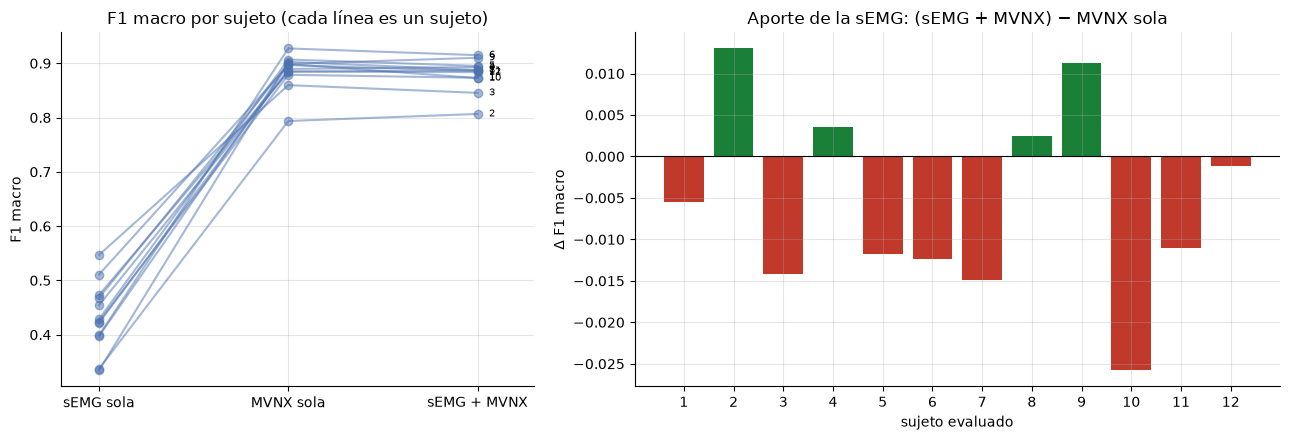

In [18]:
runs = [json.loads(p.read_text()) for p in sorted(RUN_DIR.glob("ronda_*.json"))]
assert runs, "Todavía no hay rondas terminadas."
mvnx_only = pd.DataFrame([{"sujeto": r["held_out"], "semilla": r["seed"], "F1": r["metrics"]["f1_macro"],
                           "bal_acc": r["metrics"]["balanced_accuracy"],
                           **{f"F1 {l}": f for l, f in zip(LABELS, r["metrics"]["f1_per_class"])}} for r in runs])
mvnx_only.to_csv(SUMMARY_CSV, index=False)

M_EMG, M_MV, M_BOTH = "sEMG sola (07_LOSO)", "MVNX sola", "sEMG + MVNX (08)"
MODELS = [M_EMG, M_MV, M_BOTH]
table = pd.DataFrame([{"sujeto": r["held_out"], "semilla": r["seed"], M_EMG: baseline_f1(r["held_out"], r["seed"]),
                       M_MV: r["metrics"]["f1_macro"], M_BOTH: fused_f1(r["held_out"], r["seed"])} for r in runs])
by_subject = table.groupby("sujeto")[MODELS].mean()
summary = pd.DataFrame({"media": by_subject.mean(), "desv. entre sujetos": by_subject.std(),
                        "mínimo": by_subject.min(), "máximo": by_subject.max()}).T
print(f"Rondas terminadas: {len(runs)} | semillas: {sorted(map(int, mvnx_only['semilla'].unique()))}")
display(pd.concat([by_subject, summary]).round(3))

rows = []
for a, b in ((M_MV, M_EMG), (M_BOTH, M_MV), (M_BOTH, M_EMG)):
    diff = (by_subject[a] - by_subject[b]).to_numpy()
    boot = np.array([np.random.default_rng(SEED_DATA + k).choice(diff, len(diff)).mean() for k in range(5000)])
    p = wilcoxon(diff).pvalue if len(diff) >= 5 and np.any(diff != 0) else np.nan
    rows.append({"comparación": f"{a} − {b}", "diferencia media": diff.mean(),
                 "IC 95 %": f"[{np.quantile(boot, .025):+.3f}, {np.quantile(boot, .975):+.3f}]",
                 "sujetos en que gana": f"{int((diff > 0).sum())} de {len(diff)}", "p (Wilcoxon)": p})
display(pd.DataFrame(rows).set_index("comparación").round({"diferencia media": 3, "p (Wilcoxon)": 4}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.1, 1.5]})
for s in by_subject.index:
    axes[0].plot(range(3), by_subject.loc[s, MODELS], marker="o", color="#4c72b0", alpha=0.5)
    axes[0].text(2.06, by_subject.loc[s, M_BOTH], str(s), va="center", fontsize=7)
axes[0].set(xticks=range(3), xticklabels=["sEMG sola", "MVNX sola", "sEMG + MVNX"], xlim=(-0.2, 2.3), ylabel="F1 macro",
            title="F1 macro por sujeto (cada línea es un sujeto)")
gain = by_subject[M_BOTH] - by_subject[M_MV]
axes[1].bar(by_subject.index.astype(str), gain, color=np.where(gain > 0, "#1a7f37", "#c0392b"))
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="sujeto evaluado", ylabel="Δ F1 macro", title="Aporte de la sEMG: (sEMG + MVNX) − MVNX sola")
plt.tight_layout()
plt.show()

# 10. Desempeño por actividad

Se juntan las predicciones de todos los sujetos evaluados y se calcula el F1 por actividad de los tres modelos. Interesa sobre todo la última fila: **en qué actividades agrega algo la sEMG** sobre el movimiento. Se esperaría que ayude, por ejemplo, a distinguir cargar (K) de estar de pie (N), que tienen una postura parecida pero distinta actividad muscular.

,N,LF,K,PT,LT,W,PF,F1 macro
sEMG sola (07_LOSO),0.710,0.411,0.484,0.372,0.398,0.371,0.381,0.447
MVNX sola,0.920,0.888,0.906,0.832,0.842,0.943,0.893,0.889
sEMG + MVNX (08),0.924,0.882,0.891,0.823,0.825,0.937,0.901,0.883
aporte de la sEMG (sEMG + MVNX − MVNX),0.004,-0.006,-0.015,-0.009,-0.018,-0.006,0.008,-0.006


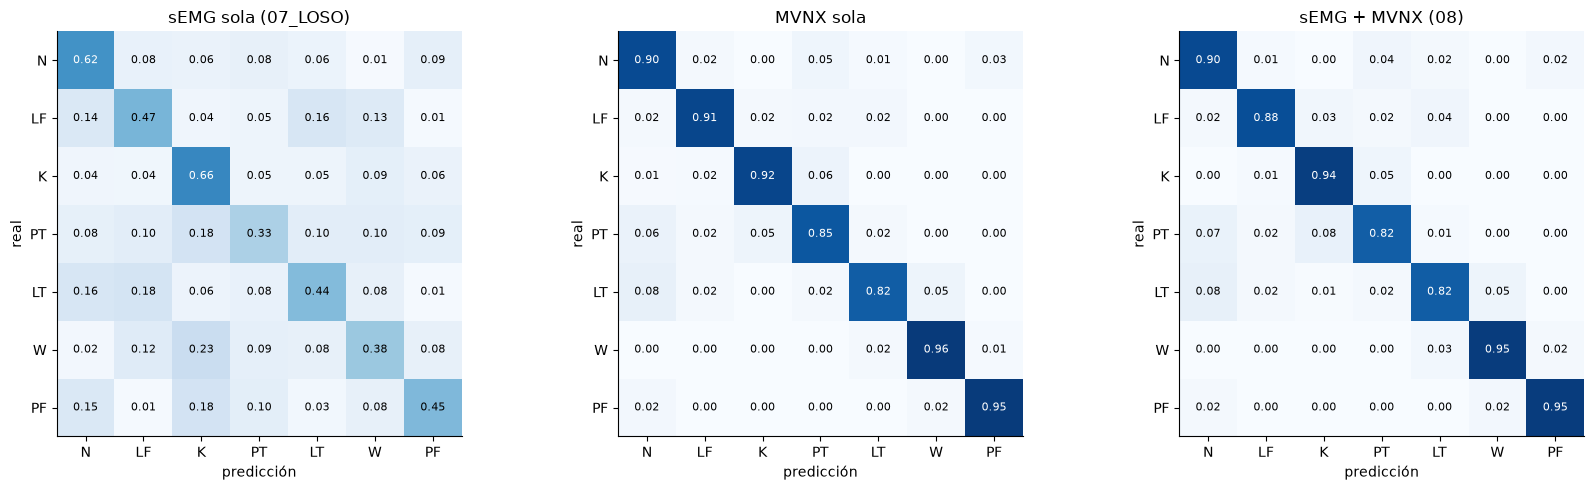

In [19]:
done = {(r["held_out"], r["seed"]) for r in runs}
y_m = np.concatenate([r["y"] for r in runs]); p_m = np.concatenate([r["pred"] for r in runs])
y_f = np.concatenate([fused_runs[k]["y"] for k in sorted(done)]); p_f = np.concatenate([fused_runs[k]["pred"] for k in sorted(done)])
base_done = baseline[[(s, k) in done for s, k in zip(baseline["sujeto"], baseline["semilla"])]]
y_b = np.concatenate(base_done["y"].to_list()); p_b = np.concatenate(base_done["pred"].to_list())
ids = list(range(len(LABELS)))
per_class = pd.DataFrame({name: f1_score(y, p, labels=ids, average=None, zero_division=0)
                          for name, y, p in ((M_EMG, y_b, p_b), (M_MV, y_m, p_m), (M_BOTH, y_f, p_f))}, index=LABELS).T
per_class["F1 macro"] = per_class.mean(axis=1)
per_class.loc["aporte de la sEMG (sEMG + MVNX − MVNX)"] = per_class.loc[M_BOTH] - per_class.loc[M_MV]
display(per_class.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, y, pr) in zip(axes, ((M_EMG, y_b, p_b), (M_MV, y_m, p_m), (M_BOTH, y_f, p_f))):
    cm = confusion_matrix(y, pr, labels=ids).astype(float)
    cm /= cm.sum(axis=1, keepdims=True)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set(xticks=ids, xticklabels=LABELS, yticks=ids, yticklabels=LABELS, xlabel="predicción", ylabel="real", title=name)
    ax.grid(False)
    for i in ids:
        for j in ids:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.55 else "black")
plt.tight_layout()
plt.show()

# 11. Por tipo de tarea y ensayos marcados

El F1 macro de las predicciones juntas de todos los sujetos, por subconjunto. En el 08, los isocinéticos fueron la tarea más difícil (F1 de 0.66). Interesa ver si ahí la sEMG aporta más que en las tareas MMH. Los ensayos marcados (`validacion_dudosa`) se incluyen como control de la sincronización.

In [20]:
trial_info = trials.set_index("trial_idx")
win_m = trial_info.loc[sup_index.loc[np.concatenate([r["index"] for r in runs]), "trial_idx"].to_numpy(), ["task", "validacion_dudosa"]]
win_f = trial_info.loc[sup_index.loc[np.concatenate([fused_runs[k]["index"] for k in sorted(done)]), "trial_idx"].to_numpy(),
                       ["task", "validacion_dudosa"]]
win_b = trials.set_index("file").loc[np.concatenate(base_done["file"].to_list()), ["task", "validacion_dudosa"]]
subsets = {"todas": lambda w: np.ones(len(w), bool), "ensayos no marcados": lambda w: ~w["validacion_dudosa"].to_numpy(),
           "ensayos marcados": lambda w: w["validacion_dudosa"].to_numpy(),
           **{f"tarea {t}": (lambda w, t=t: (w["task"] == t).to_numpy()) for t in ("Isokin", "MMH_One", "MMH_Bim")}}
rows = []
for name, sel in subsets.items():
    row = {"subconjunto": name, "ventanas": int(sel(win_m).sum())}
    for model, w, y, p in ((M_EMG, win_b, y_b, p_b), (M_MV, win_m, y_m, p_m), (M_BOTH, win_f, y_f, p_f)):
        m = sel(w)
        row[model] = f1_score(y[m], p[m], average="macro") if m.any() else np.nan
    rows.append(row)
sens = pd.DataFrame(rows).set_index("subconjunto")
sens["aporte de la sEMG"] = sens[M_BOTH] - sens[M_MV]
display(sens.round(3))

,ventanas,sEMG sola (07_LOSO),MVNX sola,sEMG + MVNX (08),aporte de la sEMG
subconjunto,,,,,
todas,51814,0.447,0.889,0.883,-0.006
ensayos no marcados,42398,0.460,0.890,0.883,-0.008
ensayos marcados,9416,0.386,0.883,0.886,0.003
tarea Isokin,12894,0.283,0.684,0.664,-0.020
tarea MMH_One,16250,0.441,0.896,0.896,0.000
tarea MMH_Bim,22670,0.446,0.889,0.883,-0.006


# 12. Cómo leer los resultados para decidir la integración

- **Si MVNX sola ≈ sEMG + MVNX** (el aporte de la sEMG tiene un IC que incluye el 0): con la fusión temprana actual, el modelo se apoya casi sólo en el movimiento. Antes de descartar la sEMG, conviene probar una **fusión tardía**, con un encoder por modalidad y concatenación de los `c_T`. Así cada modalidad aprende su propia representación y la sEMG no queda opacada por las 30 variables MVNX.
- **Si sEMG + MVNX > MVNX sola de forma consistente:** la sEMG aporta información complementaria y la fusión temprana ya la aprovecha. Las secciones 10 y 11 dicen dónde ayuda (actividades y tareas), y eso orienta mejoras como más peso a la sEMG o una fusión con atención.
- **Si MVNX sola > sEMG + MVNX:** la sEMG estaría agregando ruido o sobreajuste. Habría que revisar el escalado relativo de las dos modalidades o usar *dropout* por modalidad.
- **En cualquier caso**, faltan la semilla 1 y una sola apertura de la prueba (sujetos 13 y 14) con el modelo elegido.